# How Delhi's Buses Move

### One evening of live GPS data from 6,000 buses

**Rishabh Jain**

This notebook follows Delhi's city buses for six hours on Wednesday 21 October 2026, from 6:23 pm to 12:23 am, using the city's live bus-position feed. It answers five questions:

1. How fast do buses move, and where are roads busy or free?
2. Which stretches of road are the slowest?
3. Do buses on the same route bunch together?
4. Can arrival times be predicted?
5. How does the evening compare with the published 2023 timetable?

**Data:** Department of Transport, Government of NCT of Delhi, and IIIT-Delhi, through [Delhi Open Transit Data](https://otd.delhi.gov.in/). Basemaps from Esri. Raw data is not included in the repository.

## Setup

In [1]:
import sys
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "charts.py").exists())
sys.path.insert(0, str(ROOT / "scripts"))

import analyse_routes as routes
import build_trajectories as trajectories
import charts
import compare_2023 as compare
import explore_static as static
import model_eta as eta

charts.setup()


def show(name, width=900):
    display(Image(filename=charts.FIGURES / name, width=width))

In [2]:
# Clean the six hours of GPS positions: remove duplicates, stale positions, GPS jumps and parked buses.
traj = trajectories.classify(trajectories.mark_layovers(trajectories.add_steps(trajectories.load_positions())))
traj["time"] = pd.to_datetime(traj.vehicle_ts, unit="s", utc=True).dt.tz_convert("Asia/Kolkata")
moving = traj[traj.step == "ok"]
log = pd.read_csv(ROOT / "data" / "raw" / "realtime" / "poll_log.csv")
hour = moving.time.dt.hour
peak_speed = moving.speed_kmh[hour == 18].median()
night_speed = moving.speed_kmh[hour.isin([23, 0])].median()
print(f"{len(traj):,} positions from {traj.vehicle_id.nunique():,} buses; {len(moving):,} moving-bus steps")

5,079,171 positions from 6,065 buses; 3,626,697 moving-bus steps


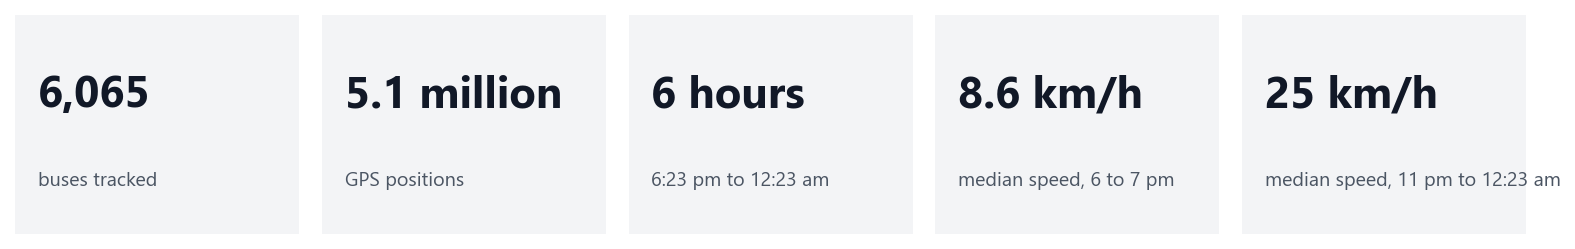

In [3]:
charts.at_a_glance([
    (f"{traj.vehicle_id.nunique():,}", "buses tracked"),
    (f"{len(traj) / 1e6:.1f} million", "GPS positions"),
    ("6 hours", "6:23 pm to 12:23 am"),
    (f"{peak_speed:.1f} km/h", "median speed, 6 to 7 pm"),
    (f"{night_speed:.0f} km/h", "median speed, 11 pm to 12:23 am"),
])
show("nb_at_a_glance.png", 1000)

## 1. The data

### 1.1 The live feed

The feed was polled every 10 seconds. Each response lists every bus with its position, route and trip.

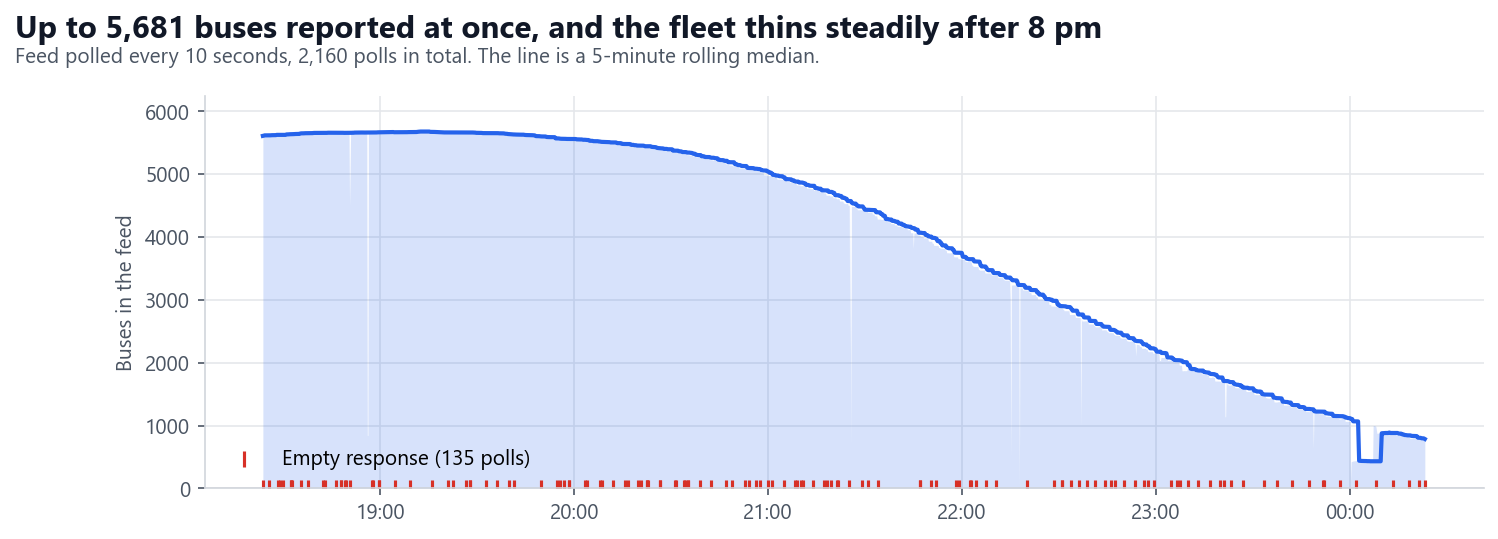

In [4]:
charts.fleet_on_road(log)
show("nb_fleet_on_road.png")

* **Over 5,600 buses** were on the road at 7 pm.
* **The fleet thins steadily after 8 pm.** By midnight, only about 1,000 buses were still running.
* **About 6% of polls came back empty** (red marks). The longest run of empty responses was 3 polls, or 30 seconds, so the gaps are short.

### 1.2 Where the buses went

Every moving bus position is placed on a 90 m grid. Brighter roads carried more buses.

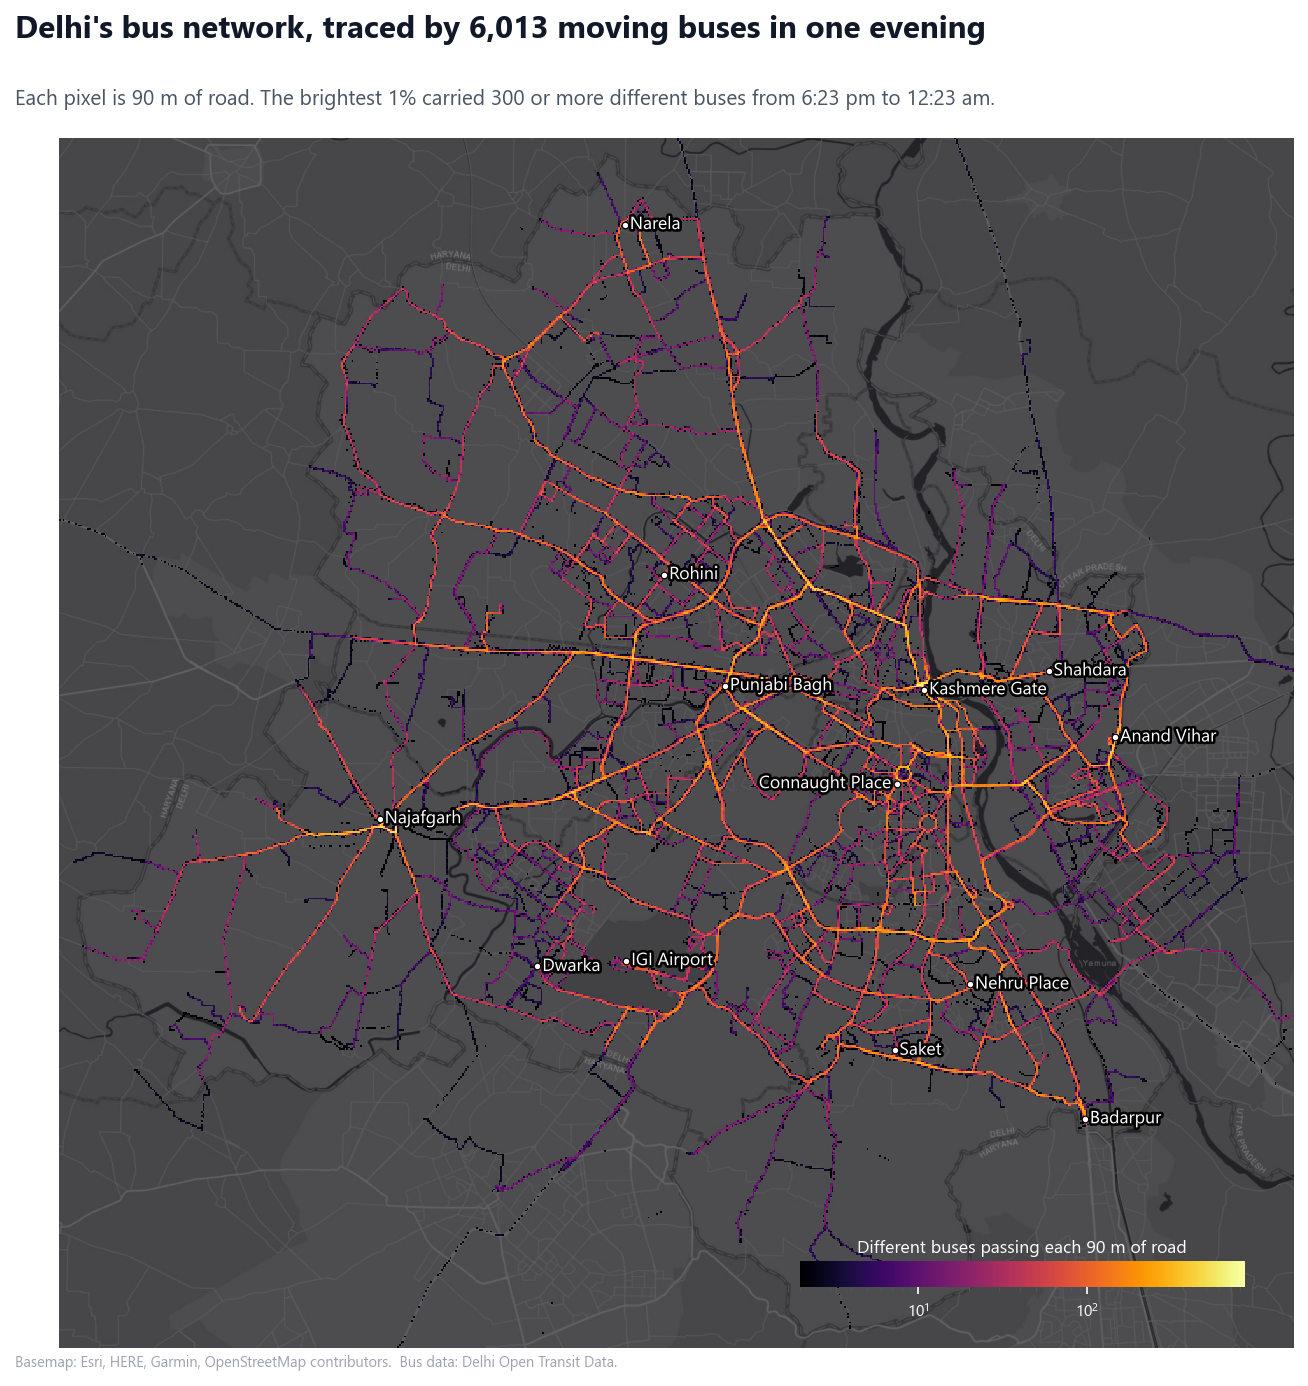

In [5]:
charts.traffic_map(moving)
show("nb_map_bus_traffic.png", 820)

* **The busiest corridors** are the Ring Road, the Outer Ring Road and the radial roads out to Najafgarh, Narela and Badarpur.
* **The network is dense in the centre and thin at the edges.** Each outer area hangs off a few main roads.

### 1.3 Why the published timetable cannot answer these questions

The 2023 timetable lists a time for every stop. Dividing the distance between stops by the scheduled time shows what speed it assumes.

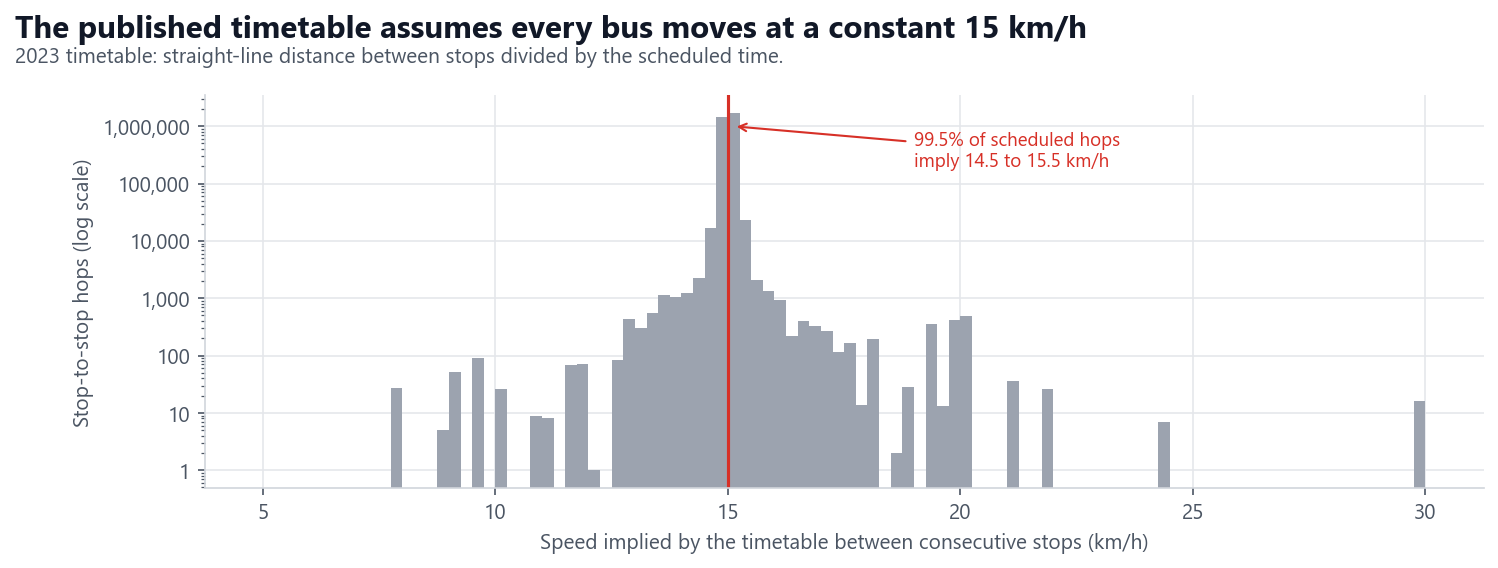

In [6]:
_, stops23, _, stop_times23 = static.load_feed(static.FEED)
_, segments23 = static.build_segments(stops23, stop_times23)
charts.timetable_speeds(segments23)
show("nb_timetable_speeds.png")

* **Almost every scheduled hop assumes exactly 15 km/h.** The portal confirms that timetable times are estimates based on a constant speed.
* **Only the live GPS feed shows how fast buses really move.** The rest of this notebook uses it.

## 2. Speed: when and where roads are busy or free

### 2.1 Through the evening

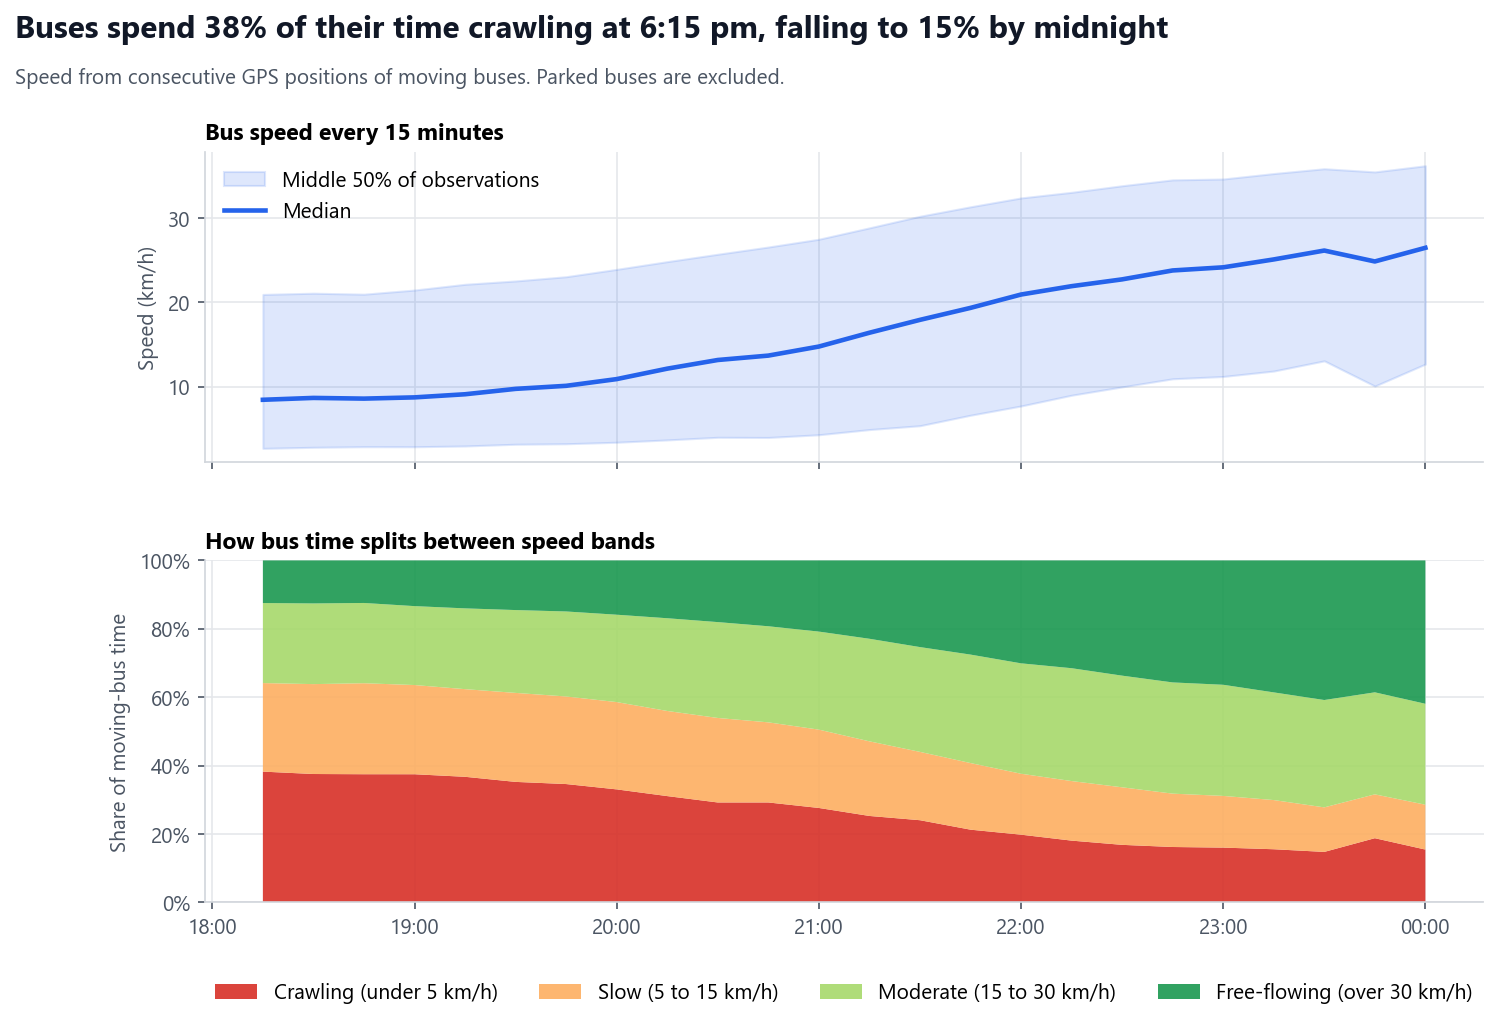

In [7]:
shares, quantiles = charts.speed_timeline(moving)
show("nb_speed_timeline.png")

* **From 6:15 to 7:30 pm, the typical bus moves at under 10 km/h,** close to a brisk cycling pace.
* **Speed rises steadily after 8 pm** and passes 20 km/h by 10 pm.
* **Crawling time (red) more than halves,** from 38% of moving time at 6:15 pm to 15% by midnight.

### 2.2 Busy roads and free roads, peak against late night

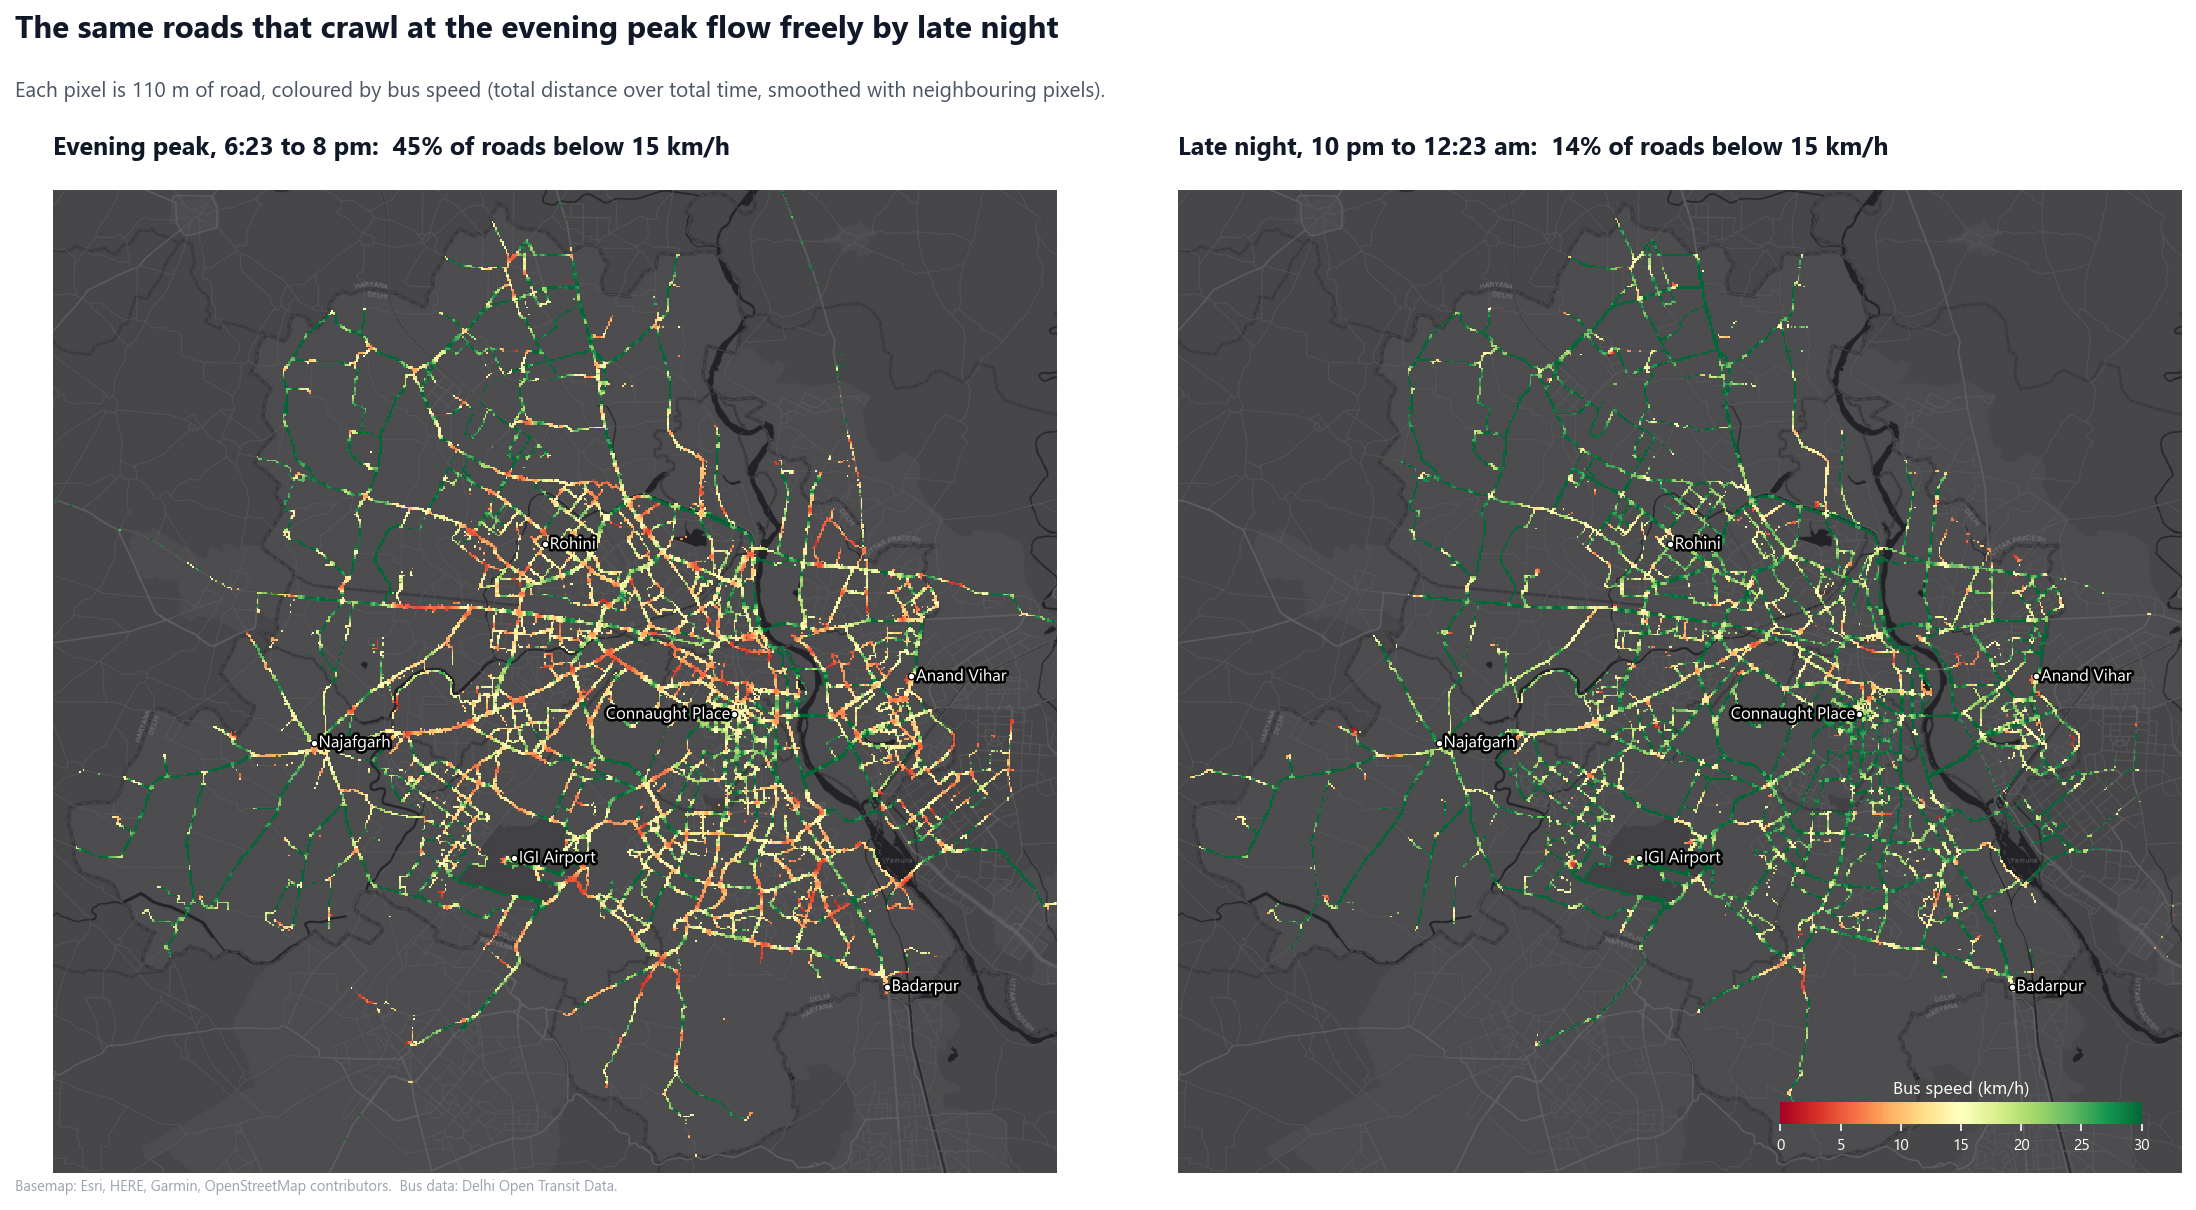

In [8]:
road_shares = charts.speed_maps(moving)
show("nb_map_speed_peak_night.png", 1000)

* **At the evening peak, about 45% of bus roads run below 15 km/h.** Red and orange stretches cover most of the city inside the Outer Ring Road.
* **By late night, that falls to about 14%.** The same roads turn green.
* **The outer radial roads stay green in both periods,** so the congestion is concentrated in the built-up core.

### 2.3 A closer look at central Delhi at the peak

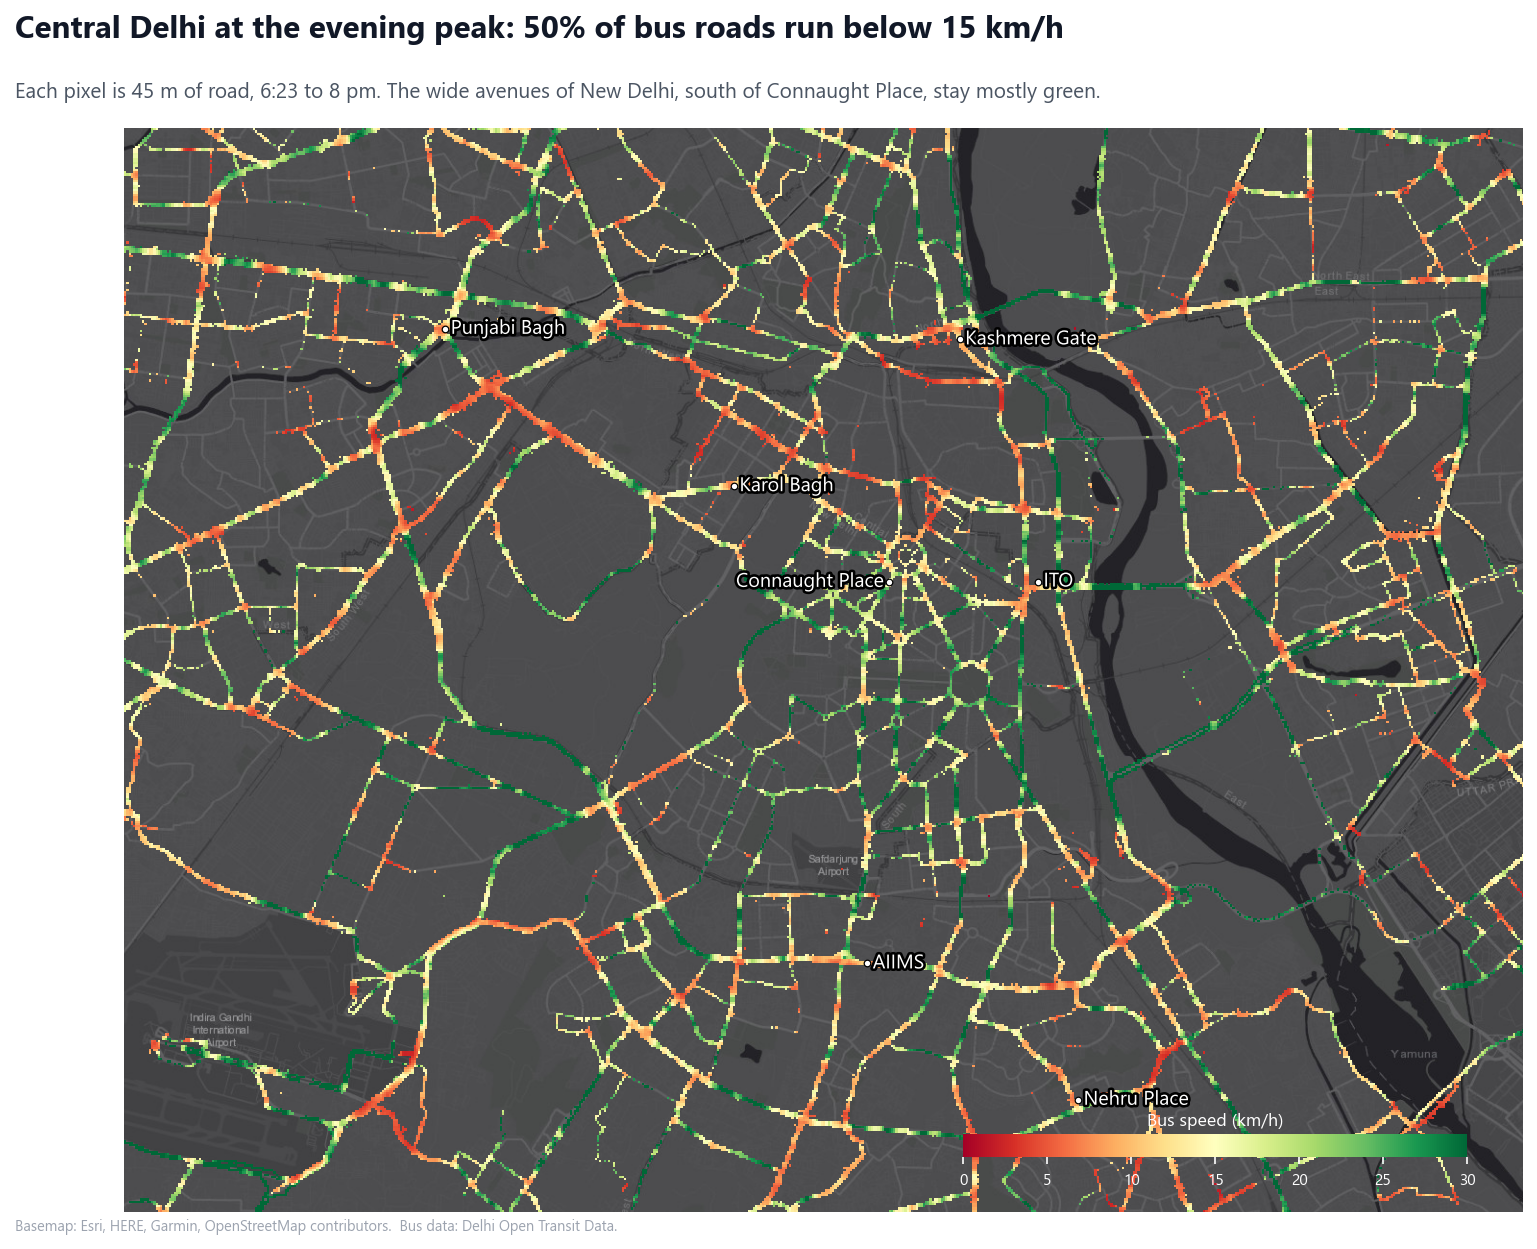

In [9]:
central_share = charts.central_map(moving)
show("nb_map_central_peak.png", 900)

* **Half of central bus roads run below 15 km/h at the peak.**
* **The roads around Karol Bagh, Punjabi Bagh and Kashmere Gate are mostly red.**
* **The wide avenues of New Delhi,** between Connaught Place and AIIMS, stay mostly green.

### 2.4 How much time the peak costs

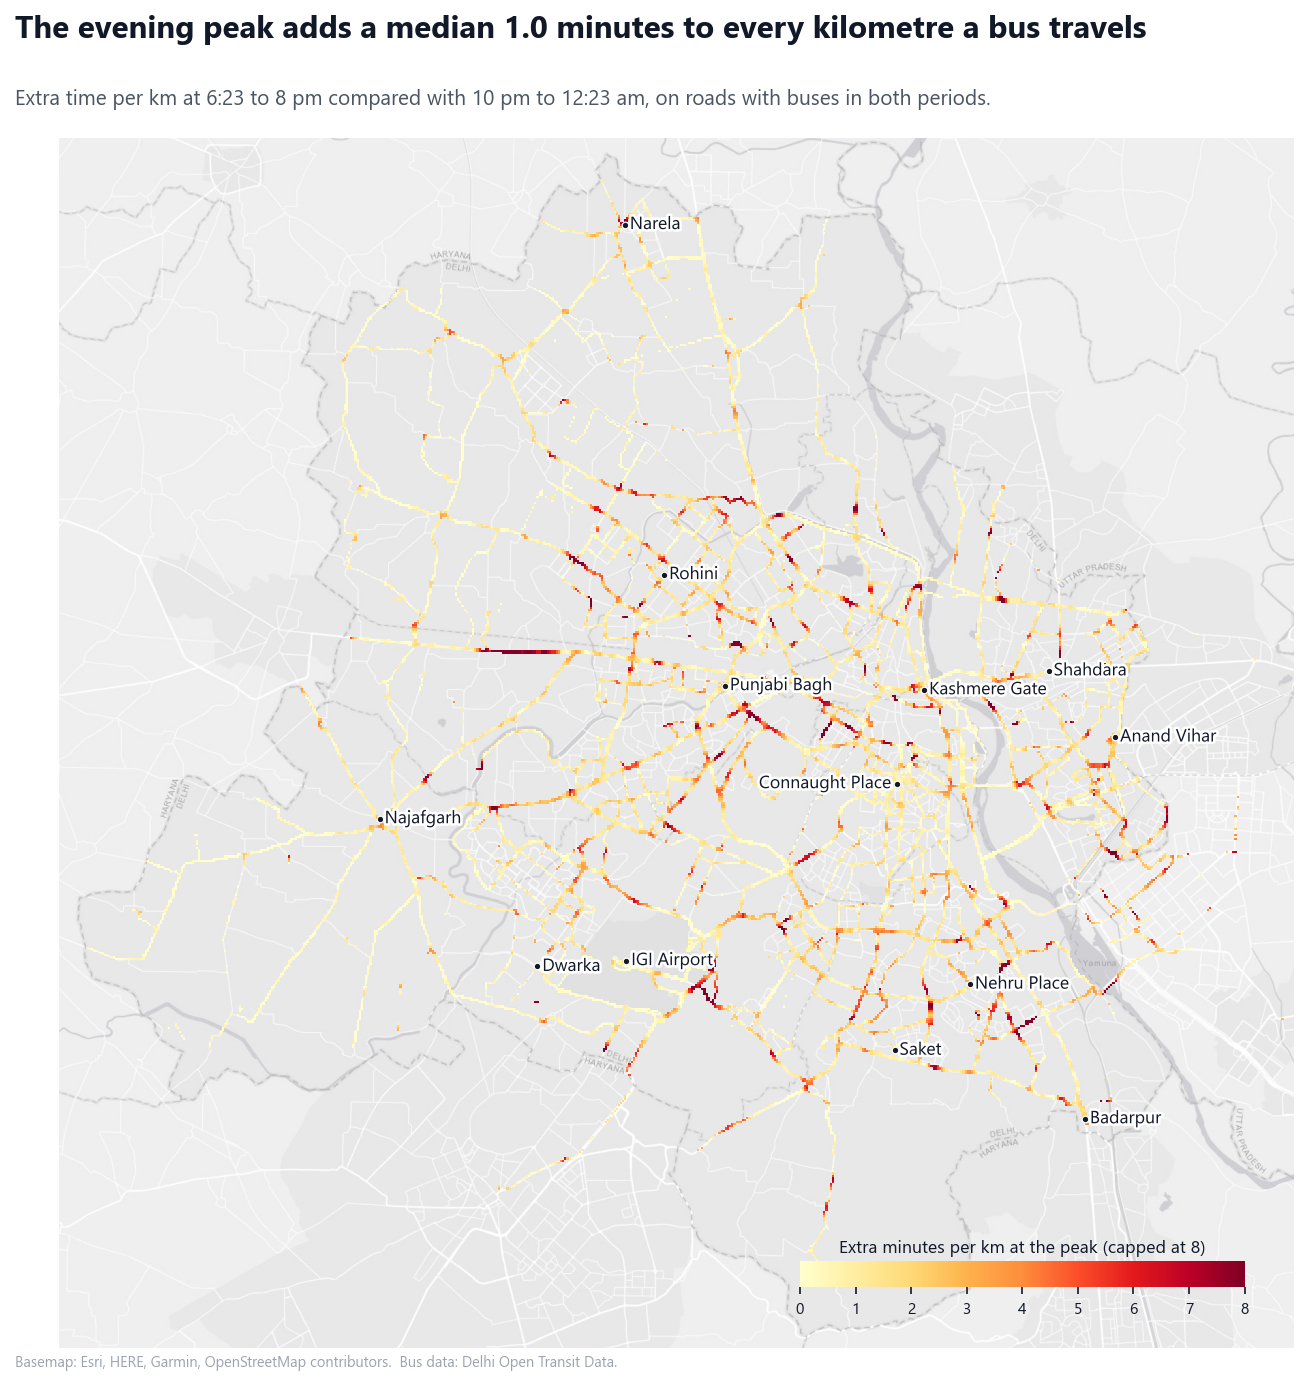

In [10]:
extra = charts.peak_cost_map(moving)
show("nb_map_peak_cost.png", 820)

* **The evening peak adds about 1 minute to every kilometre a bus travels,** on the median road.
* **About 6% of roads lose 5 minutes or more per kilometre** (dark red). They cluster in north-west Delhi around Rohini and Punjabi Bagh, on the airport road and in south Delhi near Nehru Place.

### 2.5 Distance from the centre

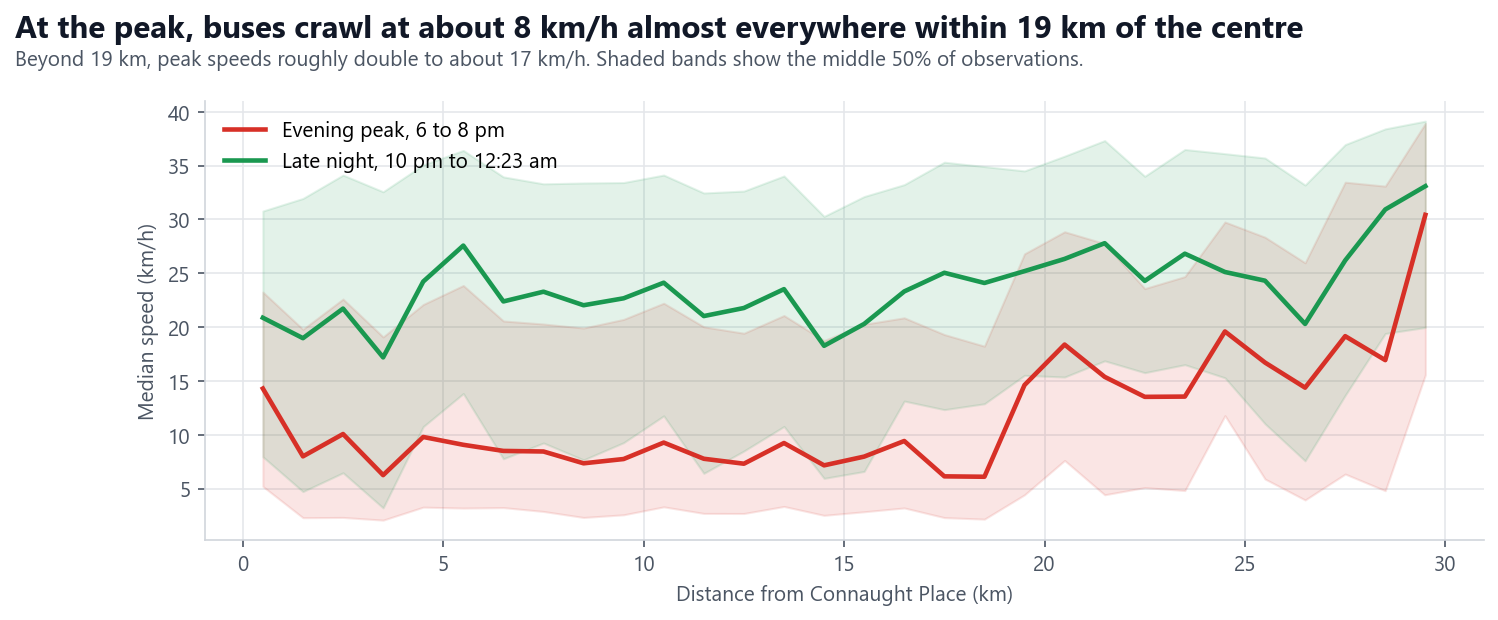

In [11]:
by_distance = charts.speed_by_distance(moving)
show("nb_speed_by_distance.png")

* **At the peak, buses crawl at about 8 km/h almost everywhere within 19 km of Connaught Place.** Congestion is not just a city-centre problem.
* **Beyond about 19 km, peak speeds roughly double.**
* **Late at night, speeds are 20 to 28 km/h almost everywhere.**

## 3. The slowest stretches

Buses were matched to stops, and the time between consecutive stops was measured. Each stretch below is at least 250 m long and was travelled by at least 10 buses.

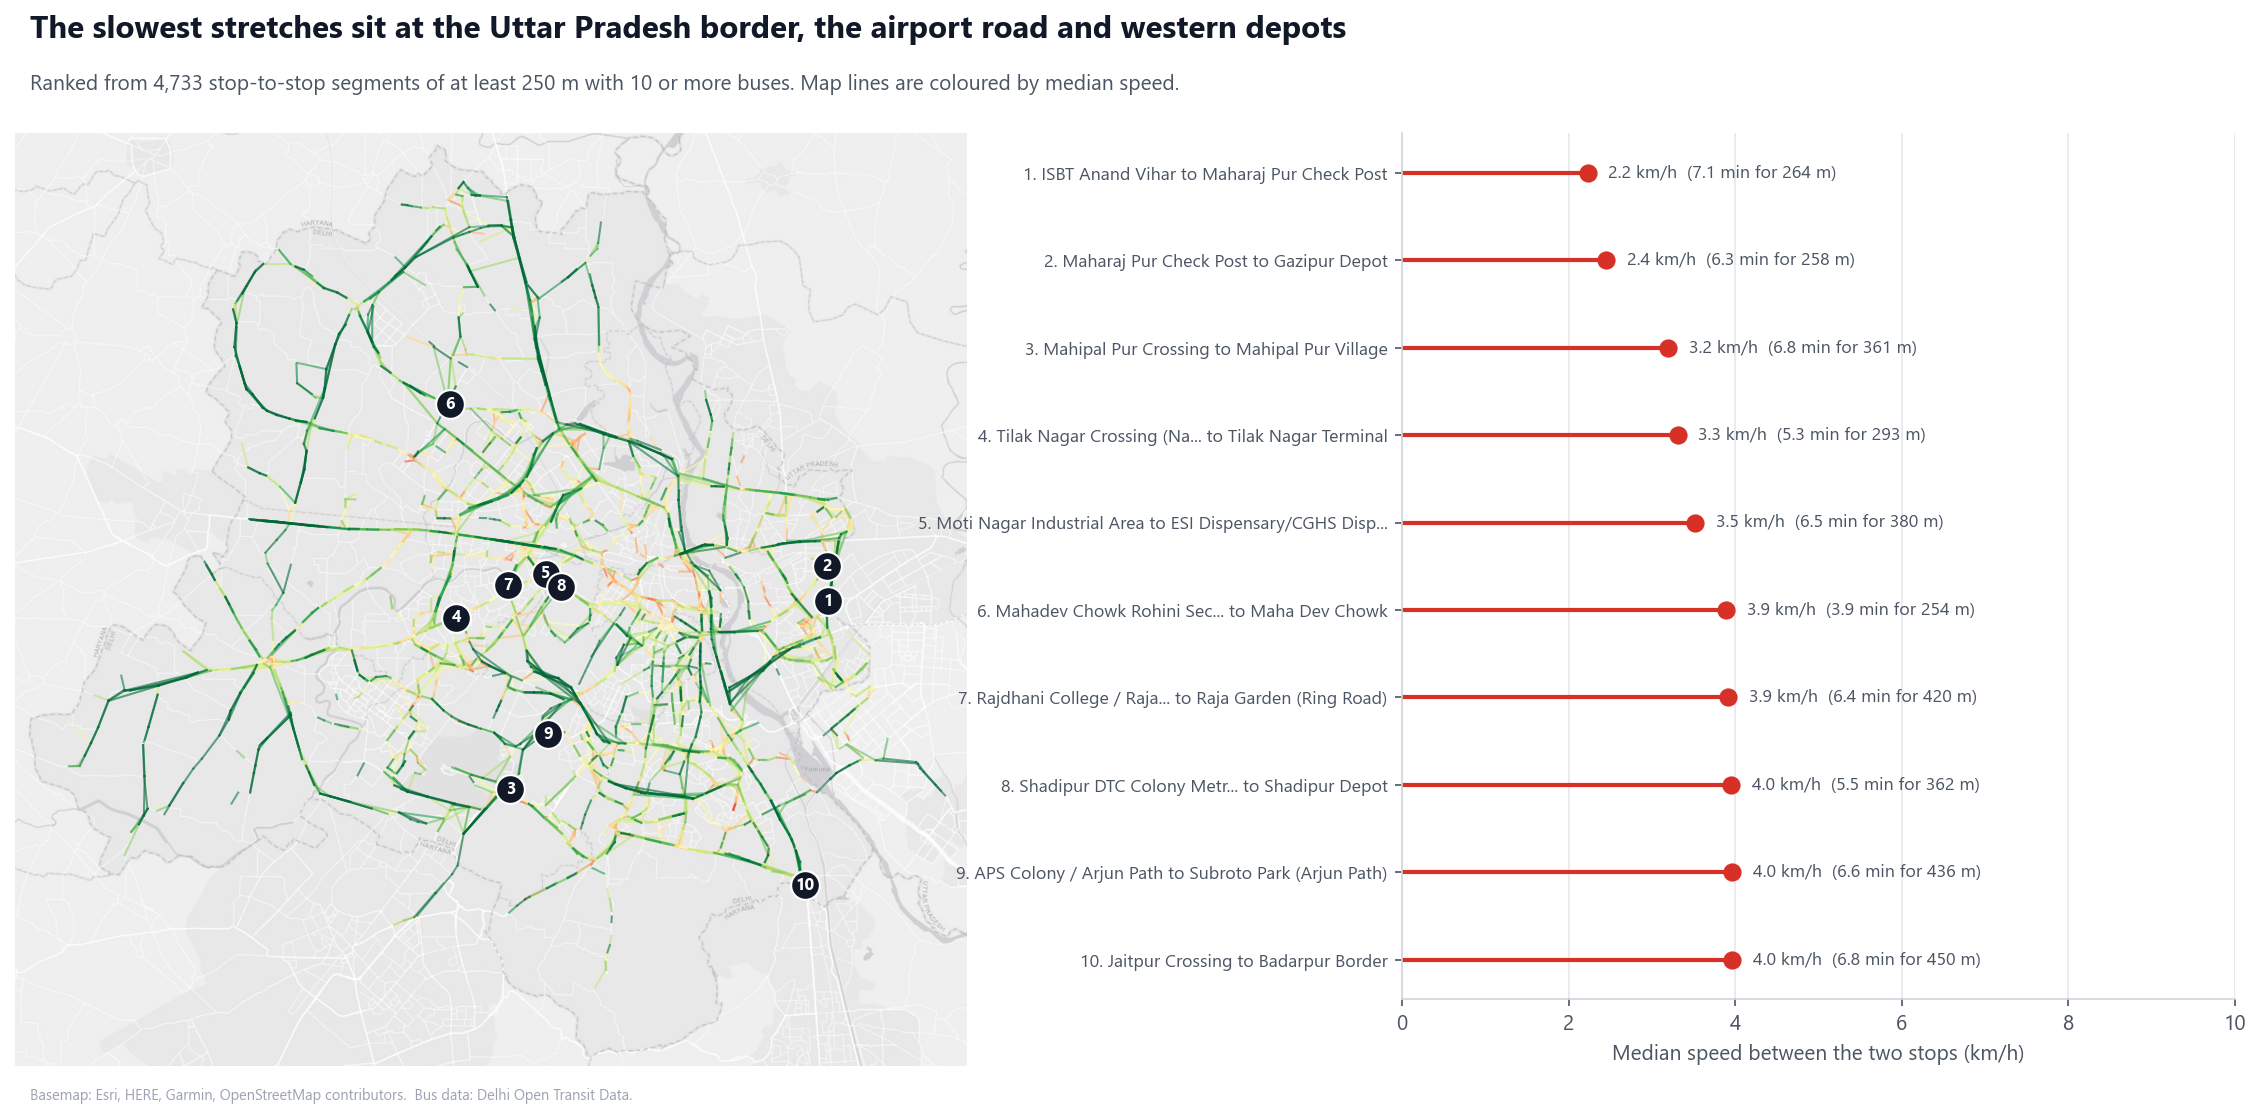

In [12]:
joined, rebuilt = routes.load()
segments, halts = routes.segments(joined, rebuilt)
ranked = routes.ranked_segments(routes.segment_stats(segments))
charts.slowest_stretches(ranked)
show("nb_slowest_stretches.png", 1000)

* **The two slowest stretches are at Anand Vihar and Gazipur** on the Uttar Pradesh border, at about 2 km/h. A bus takes about 7 minutes to cover 260 m.
* **Mahipalpur on NH-48,** the road to the airport, is third at about 3 km/h.
* **Several slow stretches end at a depot or terminal,** such as Gazipur Depot and Shadipur Depot. Part of their time is queuing to enter.

## 4. Bunching

A bus is "bunched" when it reaches a stop within 2 minutes of the previous bus on the same route. Passengers then wait longer for the bus after that.

### 4.1 One route, two hours

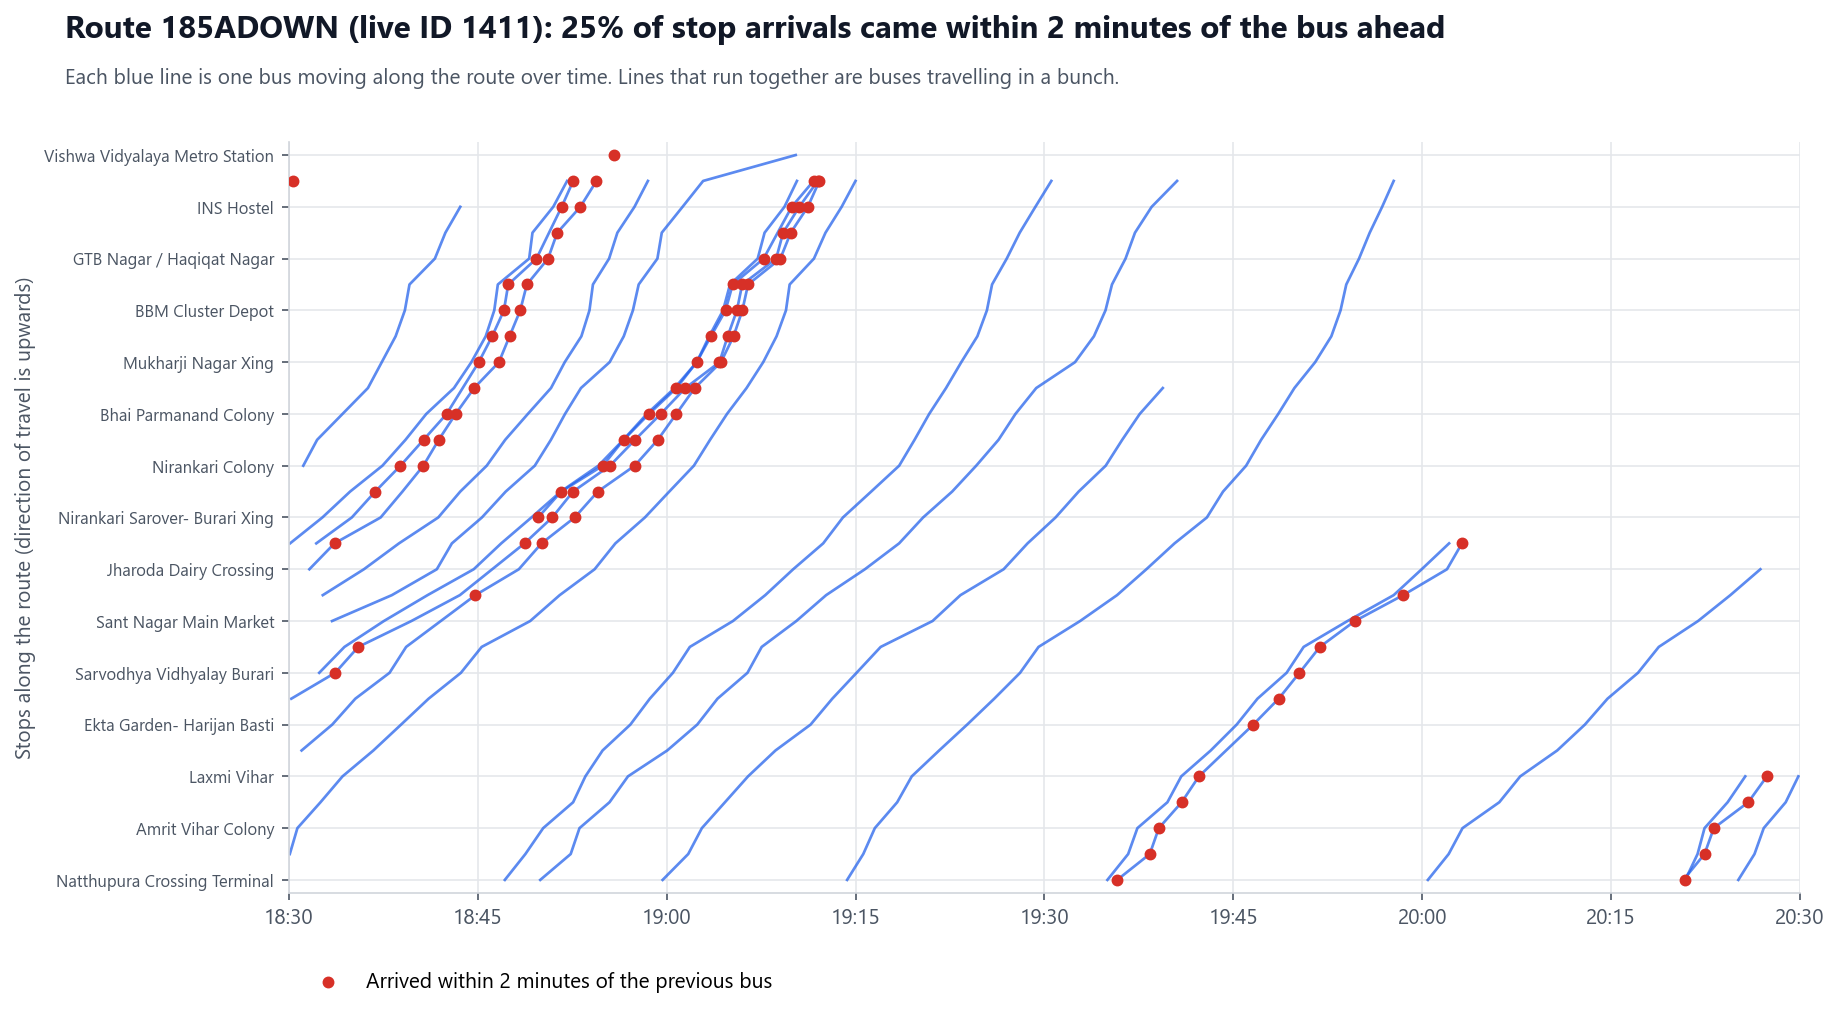

In [13]:
geometry = eta.route_geometry()
passages = eta.passages(geometry)
matches = pd.read_parquet(ROOT / "data" / "processed" / "route_matches.parquet").set_index("live_route")
route_id = "1411"
stop_names = rebuilt[rebuilt.route_id == route_id].set_index("seq").stop_name.to_dict()
start = pd.Timestamp("2026-10-21 18:30", tz="Asia/Kolkata").timestamp()
charts.time_space(passages[passages.route_id == route_id], stop_names,
                  f"{matches.loc[route_id, 'route_long_name']} (live ID {route_id})", start, start + 2 * 3600)
show("nb_bunching_time_space.png", 1000)

* **How to read this chart:** time runs left to right, and each blue line is one bus moving up the route. Evenly spaced lines would mean even service.
* **Around 7 pm, buses arrive in clusters.** At CV Raman ITI, halfway along the route, four buses came within 3 minutes (6:51 to 6:54 pm). The next bus took 6 minutes, and the one after that 16 minutes.
* This route is the 2023 route 185A, towards Vishwa Vidyalaya Metro Station.

### 4.2 Across the whole city

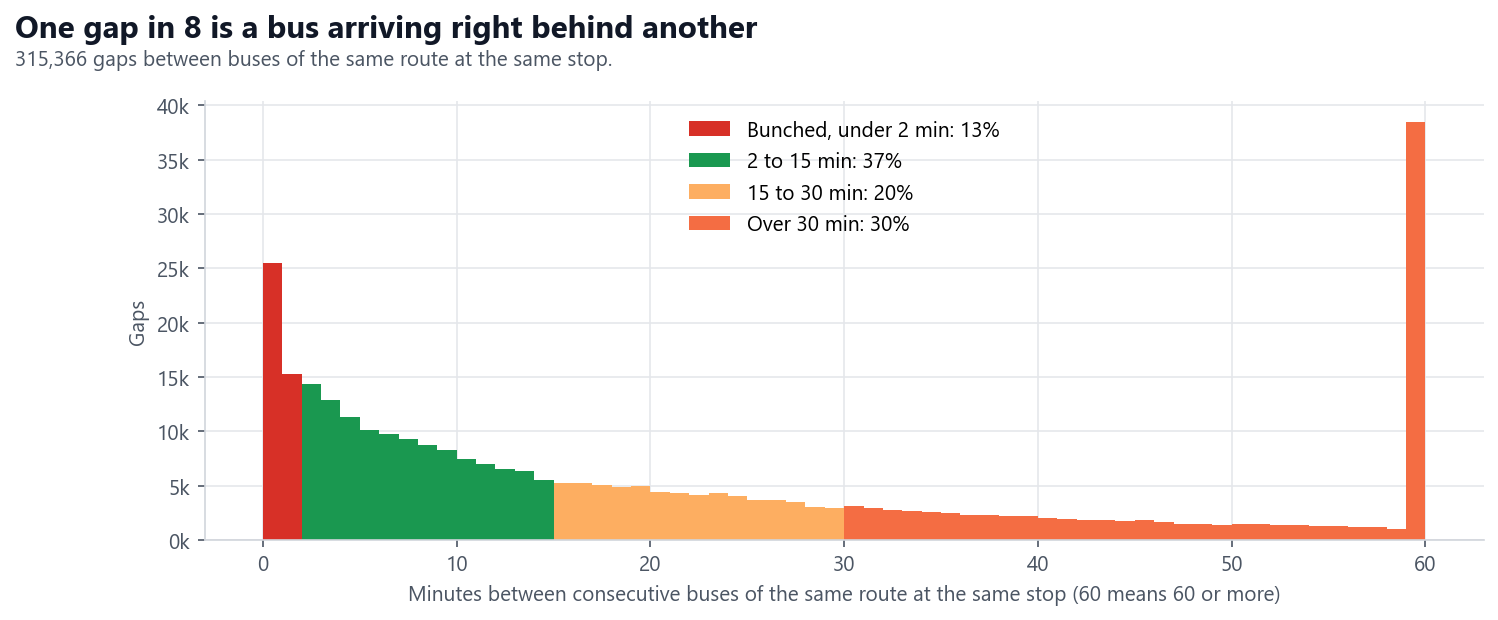

In [14]:
gaps, by_route = routes.headways(joined)
charts.headway_zones(gaps)
show("nb_headway_zones.png")

* **About one gap in eight is under 2 minutes,** meaning a bus arrived right behind another.
* **About 30% of gaps are over 30 minutes,** partly from low-frequency routes and partly from service thinning late at night.

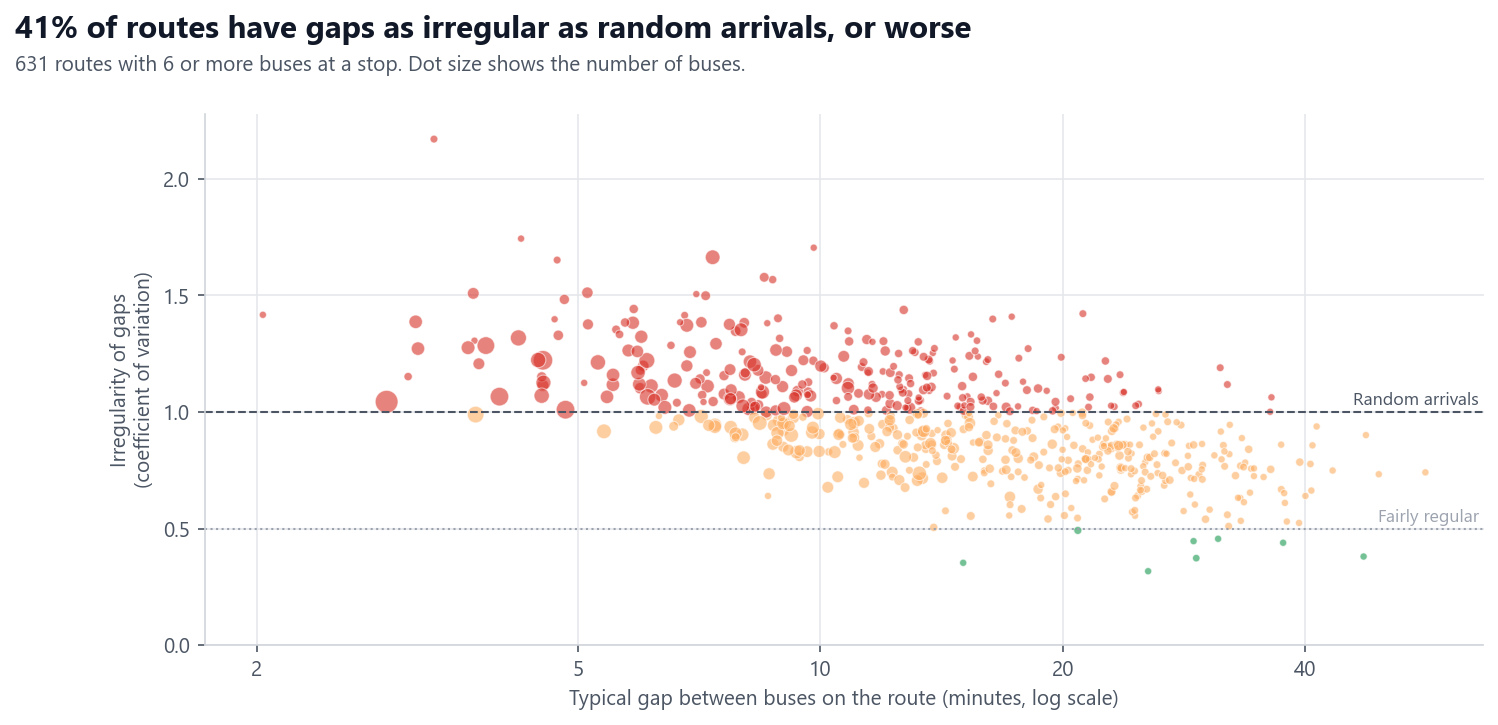

In [15]:
irregular = charts.route_reliability(by_route)
show("nb_route_reliability.png")

* **Each dot is a route.** Higher dots have more irregular gaps between buses.
* **About 41% of routes are as irregular as random arrivals, or worse** (red dots above the dashed line).
* **Frequent routes, on the left, are the most irregular.** On these routes, buses catch up with each other most easily.

## 5. Predicting arrival times

**Task:** when a bus reaches a stop, predict when it will reach each of its next 1 to 10 stops.

**Methods compared**

* **Historical median:** the typical time this evening for the same route, stop and distance.
* **Own recent speed:** the bus's speed over its last three stops.
* **LightGBM:** a gradient-boosted model using distance, stop, route, time of evening and the live speed of buses ahead.

**Tests:** with only one evening of data, the model is tested three ways.

| Test | Training data | Test data |
| --- | --- | --- |
| Later evening | First 75% of the evening | Last 25% |
| Same hours | Alternate 30-minute blocks | The other blocks |
| Unseen routes | Three quarters of routes | The remaining quarter |

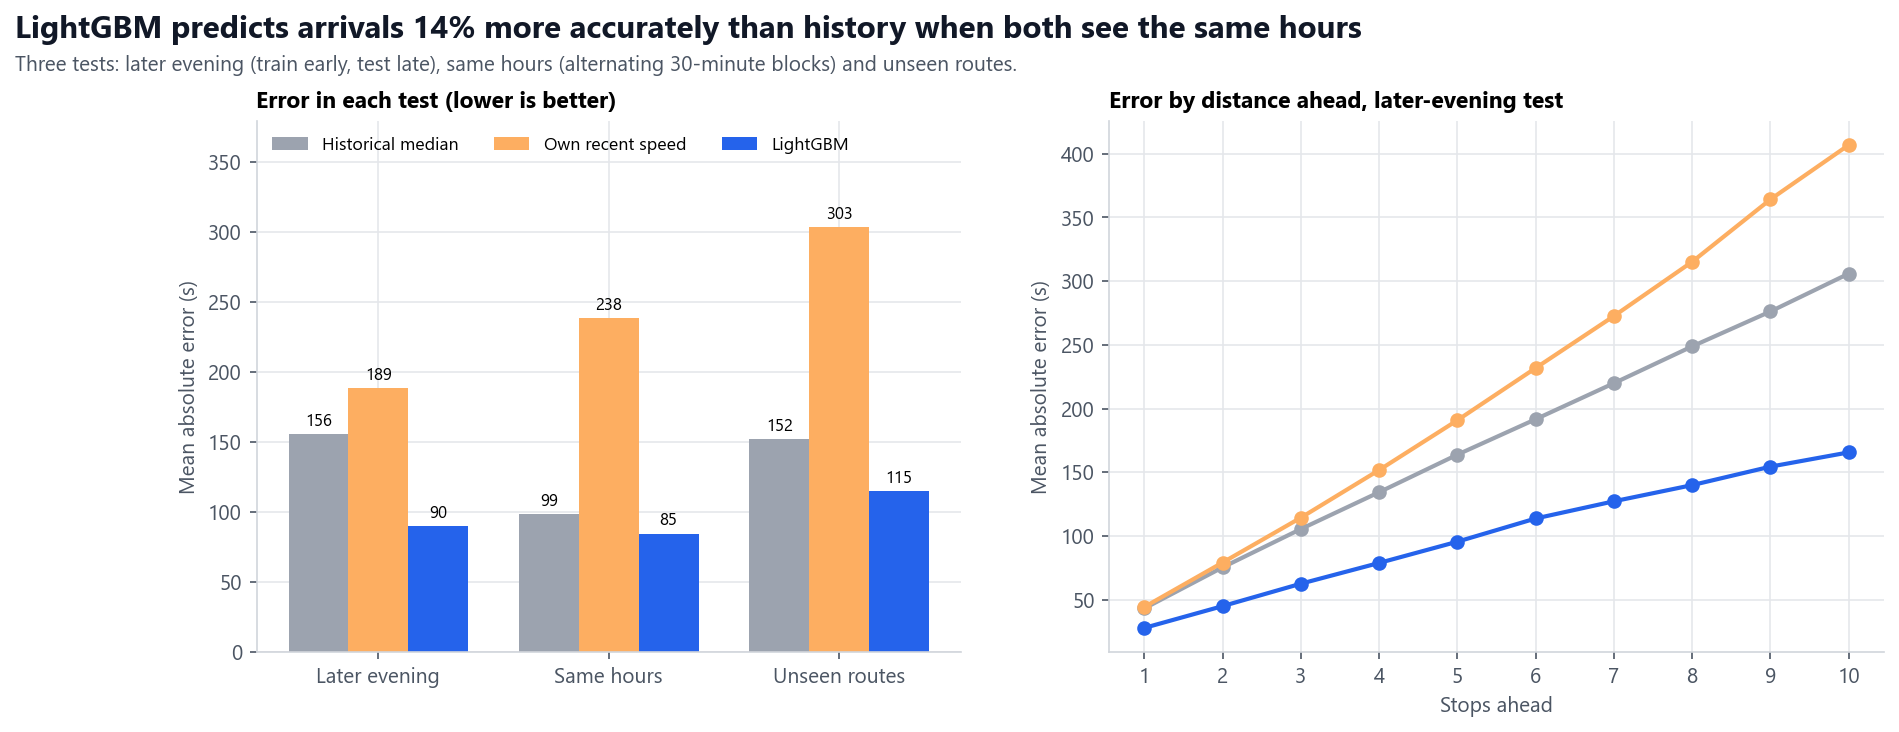

,Historical median MAE (s),Own recent speed MAE (s),LightGBM MAE (s)
Later evening,155.8,188.6,89.9
Same hours,98.8,238.3,84.6
Unseen routes,151.7,303.3,115.2


In [16]:
examples = eta.examples(passages, eta.live_segment_speeds(passages))
train, test, _ = eta.split(examples)
tests = {"Later evening": (train, test), "Same hours": eta.same_hours_split(examples),
         "Unseen routes": eta.unseen_routes_split(examples)}
rows, later_results, importance = {}, None, None
for name, (tr, te) in tests.items():
    results, imp = eta.evaluate(tr, te)
    rows[name] = {f"{method} MAE (s)": r["mae_s"] for method, r in results.items()}
    if name == "Later evening":
        later_results, importance = results, imp
table = pd.DataFrame(rows).T
charts.eta_results(table, later_results)
show("nb_eta_results.png", 1000)
table.round(1)

* **LightGBM is 14% more accurate than the historical median** when both are trained and tested on the same hours of the evening.
* **On routes it has never seen, LightGBM is 24% more accurate.** It learns general patterns rather than memorising each route.
* **The later-evening test looks more impressive (42%)** only because history from the 6 pm peak is a poor guide to lighter late-night traffic.
* **Error grows with distance.** Ten stops ahead, LightGBM is off by about 2.8 minutes, compared with about 5 minutes for history.

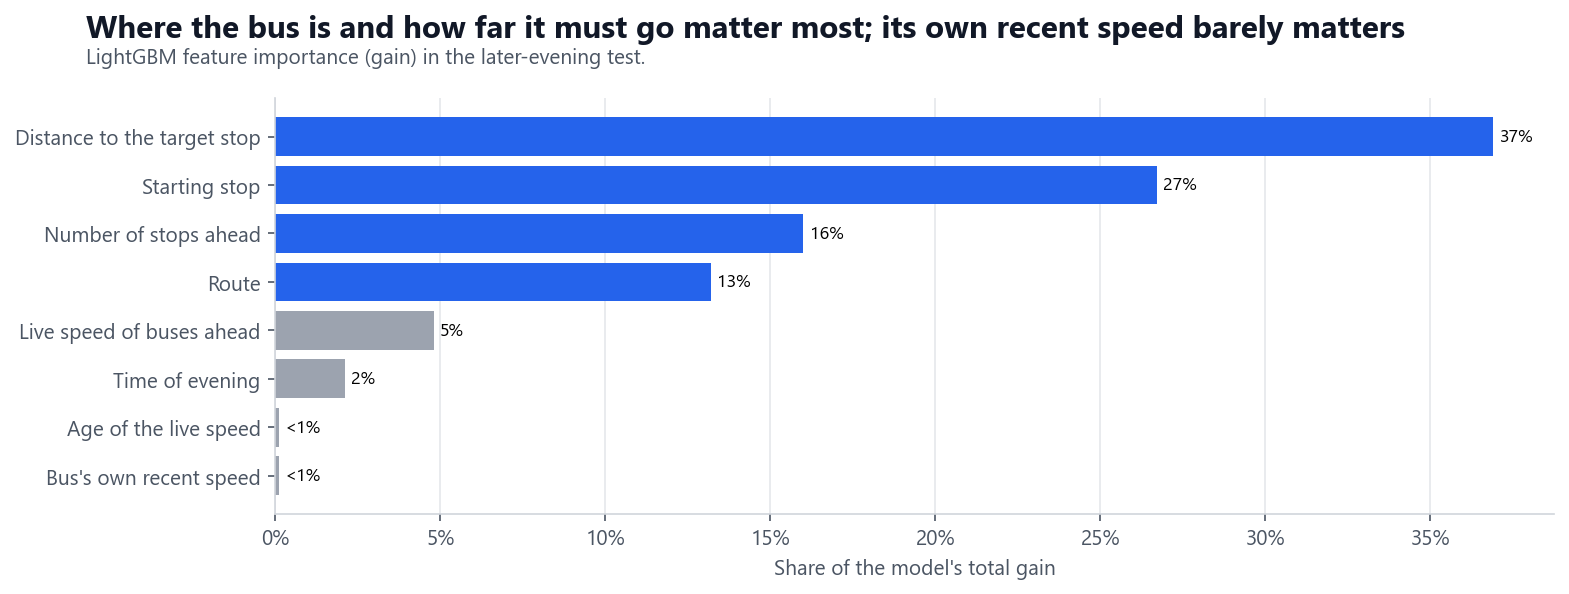

In [17]:
charts.eta_features(importance)
show("nb_eta_features.png")

* **Distance and the starting stop carry about two-thirds of the model's gain.**
* **The live speed of buses ahead adds about 5%.**
* **A bus's own recent speed adds almost nothing.** How fast it has been going says little about the road ahead.

## 6. Comparison with the 2023 timetable

The two snapshots are three and a half years apart, so differences show change since 2023, not service failures.

### 6.1 Timetable times against real times

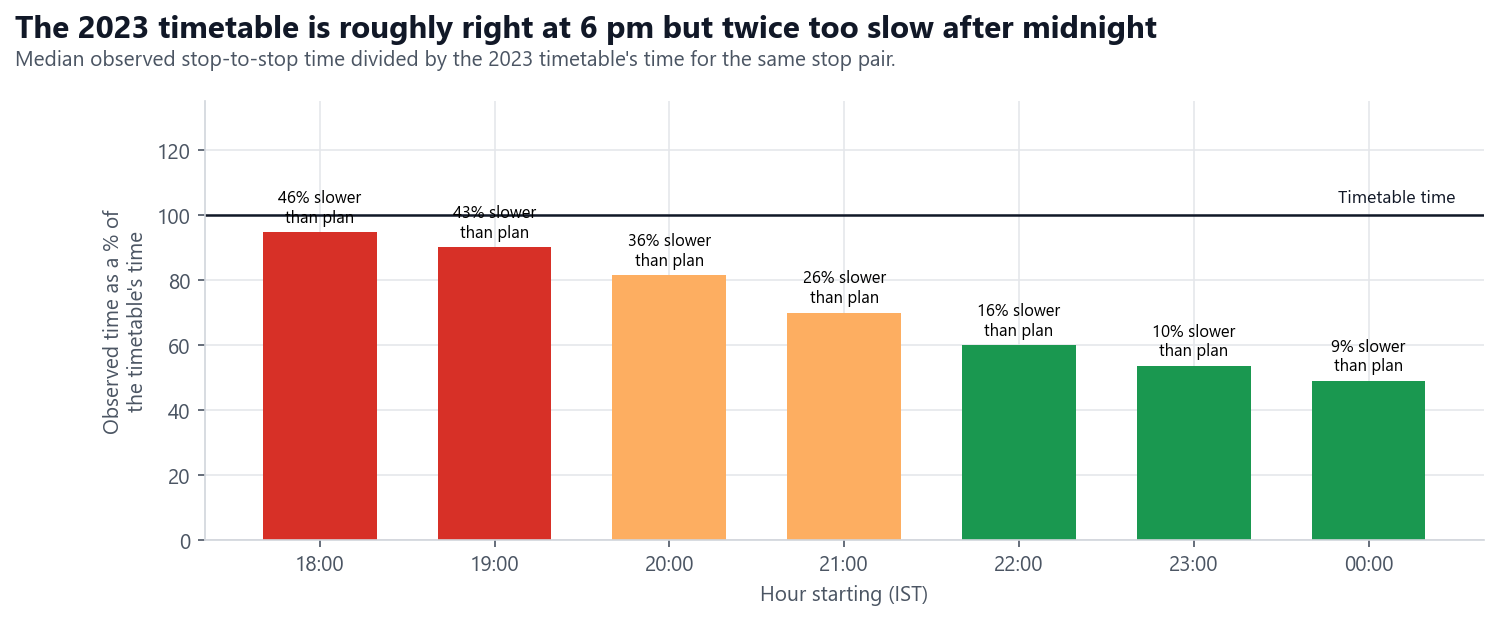

In [18]:
routes_2023, trips_2023, seq_2023 = compare.load_2023()
route_matches = compare.match_routes(seq_2023, routes_2023)
_, hourly = compare.timetable_vs_observed(seq_2023)
charts.timetable_ratio(hourly)
show("nb_timetable_ratio.png")

* **At the 6 pm peak, the timetable is close on average,** but 46% of trips take longer than it says.
* **After midnight, buses take half the time the timetable shows.**
* **An app using the published timetable would be wrong in both directions.**

### 6.2 Evening service on matched routes

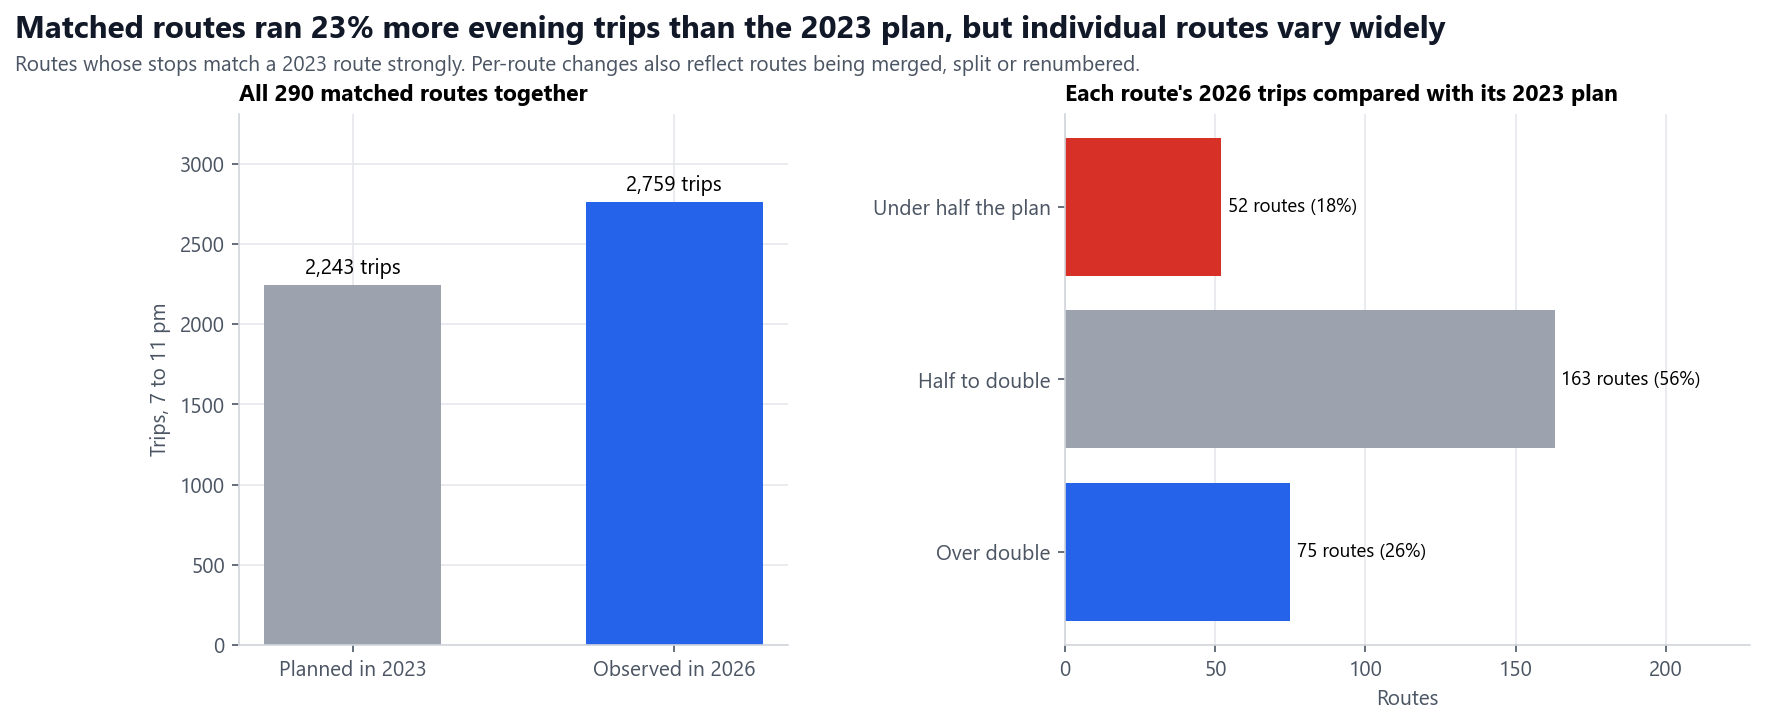

tier
partial    798
strong     368
none       255


In [19]:
frequency = compare.frequency_vs_2023(route_matches, trips_2023)
change = charts.planned_vs_observed(frequency)
show("nb_planned_vs_observed.png", 1000)
print(route_matches.tier.value_counts().rename("live routes").to_string())

* **368 live routes match a 2023 route strongly** by their stops. Their route numbers changed after 2023.
* **Matched routes ran 23% more trips between 7 and 11 pm** than planned in 2023.
* **Individual routes vary widely.** Some routes were probably merged, split or renumbered, so the total is the fairest summary.

### 6.3 Network footprint and fleet

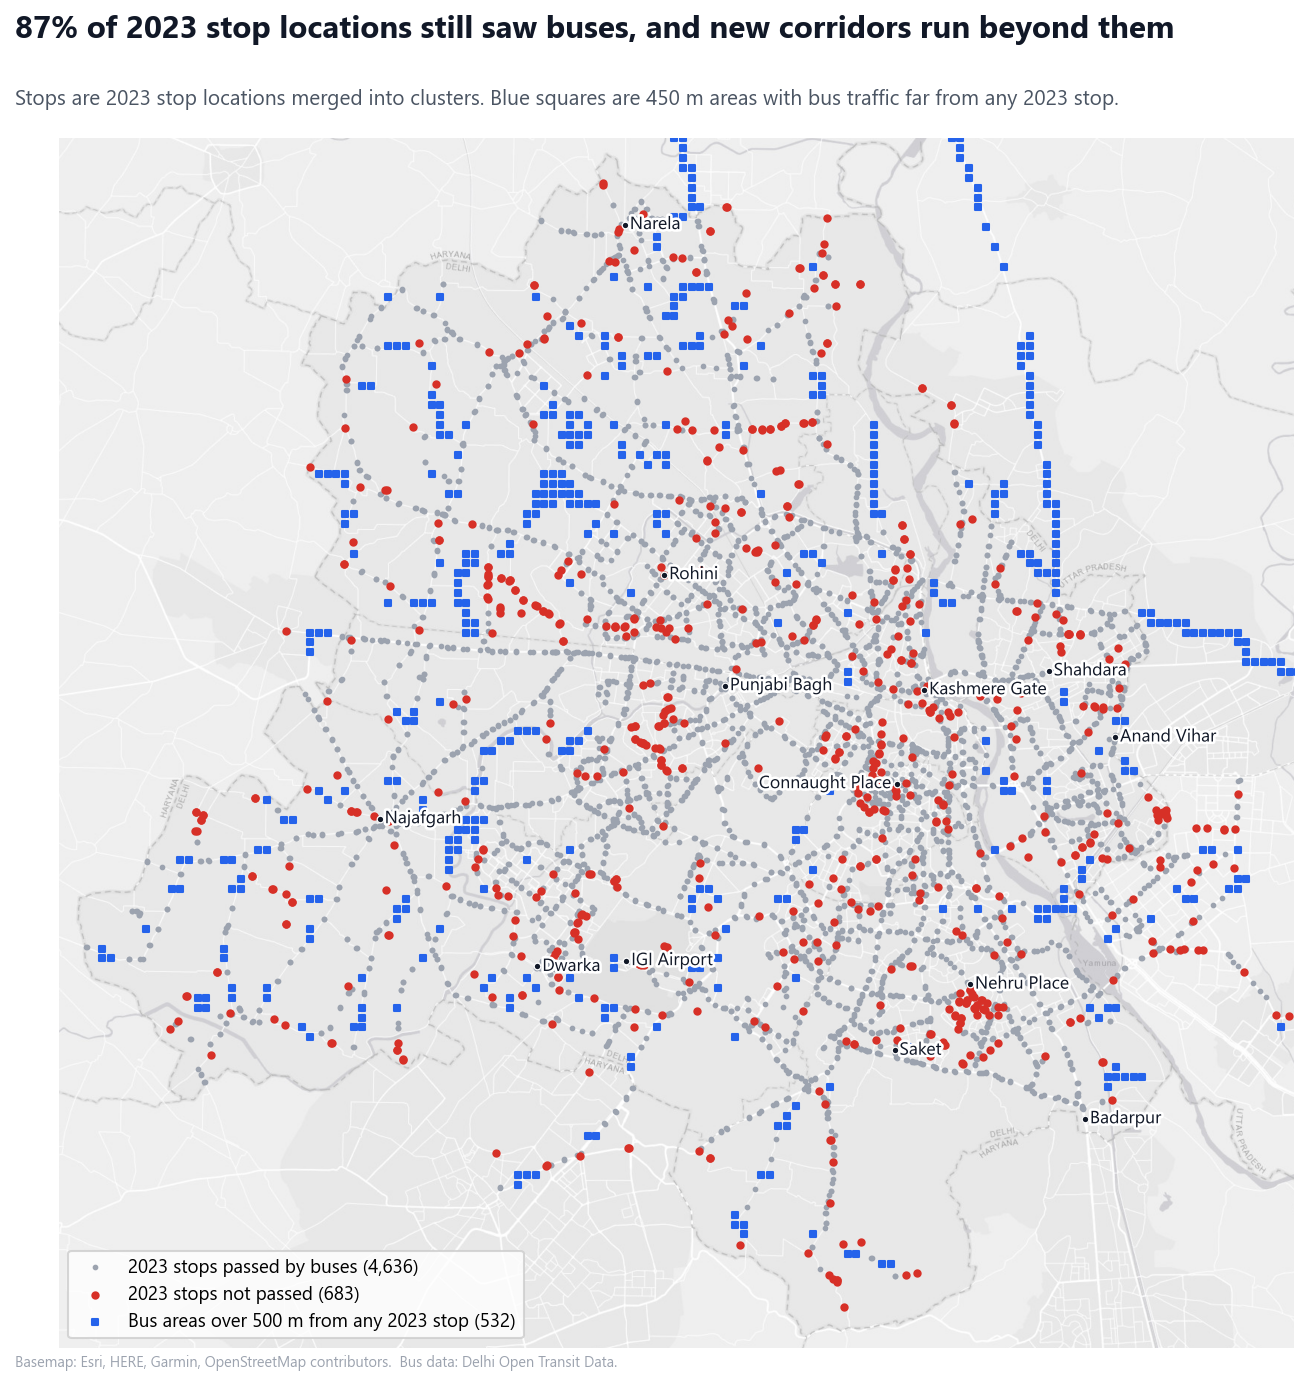

In [20]:
stop_use, bus_cells = compare.network_change(traj)
charts.network_change_map(stop_use, bus_cells)
show("nb_map_network_change.png", 820)

* **87% of 2023 stop locations still saw buses,** so the network covers largely the same ground.
* **Stops not passed (red) cluster in central and south Delhi.** They may have moved, closed or had no evening service.
* **Blue areas are bus roads far from any 2023 stop,** including corridors towards Ghaziabad in the east and Sonipat in the north. These may be new routes.

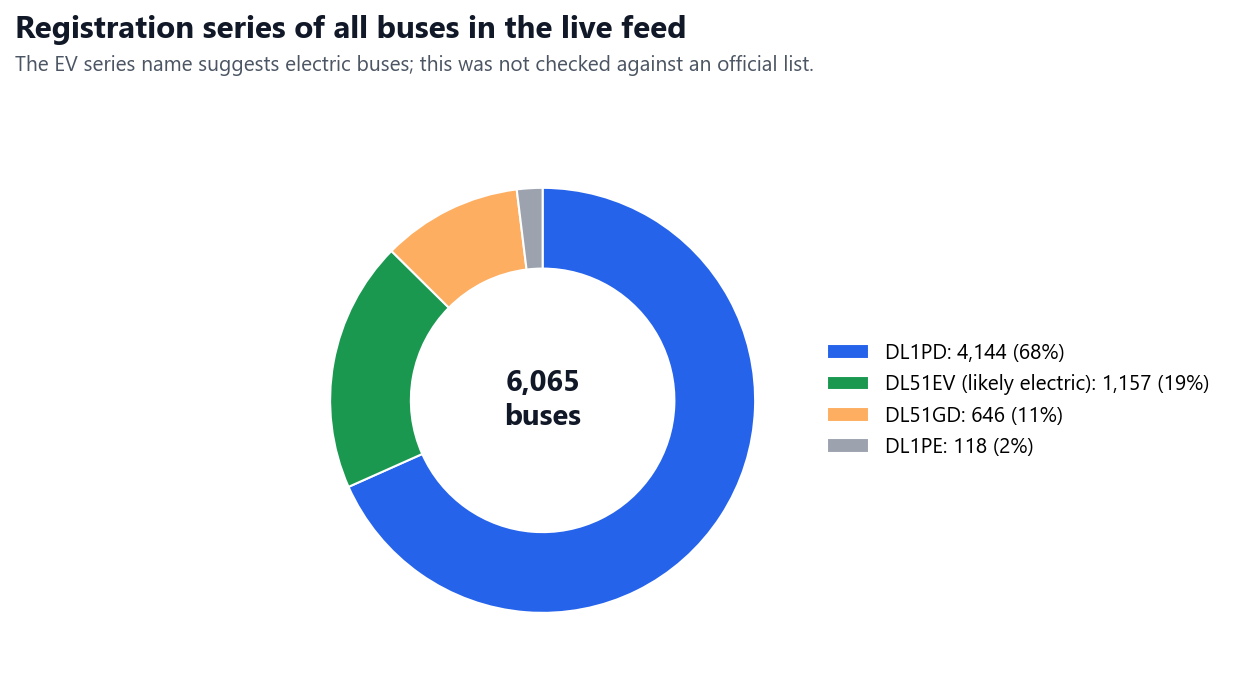

In [21]:
series, total = compare.fleet(traj)
charts.fleet_mix(series, total)
show("nb_fleet_mix.png", 700)

* **About one bus in five carries a `DL51EV` plate,** a series that suggests electric buses.

## 7. Conclusions

| Question | Answer |
| --- | --- |
| How fast are buses? | Under 10 km/h at the 6 pm peak, rising to about 25 km/h after 11 pm |
| Where are roads busy? | Almost everywhere within 19 km of the centre at the peak. North-west Delhi, the airport road and the Uttar Pradesh border are worst |
| Slowest stretches | Anand Vihar to Gazipur, at about 2 km/h |
| Bunching | One gap in eight is under 2 minutes, and 41% of routes are as irregular as random arrivals |
| Arrival prediction | LightGBM beats history by 14% on familiar routes and 24% on new ones |
| Change since 2023 | The timetable's 15 km/h is wrong in both directions, and matched routes run 23% more evening trips |

**Limitations**

* **One weekday evening only.** There is no morning peak, weekend or day-to-day comparison.
* **Straight-line distances** between stops slightly understate road speeds.
* **Stop locations come from 2023,** so new stops are missed.
* **Route names are inferred** for the 368 strongly matched routes only.